In [ ]:
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Ready:  {device}")

Ready:  cpu


In [ ]:
# Normalize images to [-1, 1] range

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

dataset = datasets.MNIST(root='./scratch/data', train=True, download=True, transform=transform)

loader = torch.utils.data.DataLoader(torch.utils.data.Subset(dataset, range(2000)), batch_size=64, shuffle=True)

print(f"Loaded (len(loader.dataset)) training samples.")


100%|██████████| 9.91M/9.91M [00:00<00:00, 41.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.25MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.83MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.46MB/s]

Loaded (len(loader.dataset)) training samples.


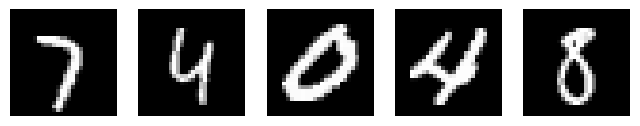

In [ ]:
real_batch, _ = next(iter(loader))
plt.figure(figsize=(8, 2))
for i in range(5):
  plt.subplot(1, 10, i+1);
  plt.imshow(real_batch[i].squeeze(), cmap='gray');
  plt.axis('off')
plt.show()

In [ ]:
generator = nn.Sequential(
    nn.Linear(64,128), nn.LeakyReLU(0.2),
    nn.Linear(128,256), nn.BatchNorm1d(256),nn.LeakyReLU(0.2),
    nn.Linear(256,784), nn.Tanh()
).to(device)
print(generator)

Sequential(
  (0): Linear(in_features=64, out_features=128, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=128, out_features=256, bias=True)
  (3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Linear(in_features=256, out_features=784, bias=True)
  (6): Tanh()
)


In [8]:
discriminator = nn. Sequential(

nn.Linear(784, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3), nn. Linear(256, 128), nn.LeakyReLU(0.2), nn.Dropout(0.3), nn.Linear(128, 1), nn. Sigmoid()

).to(device)

print("Discriminator built:", discriminator)

Discriminator built: Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=128, out_features=1, bias=True)
  (7): Sigmoid()
)


In [2]:
#fun1 = train discriminator on real and fake batches
def train_discriminator(real_x):

  opt_d.zero_grad()
  b = real_x.size(0)
  loss_real = criterion(discriminator(real_x), torch.ones (b, 1, device=device))
  fake_x = generator(torch.randn(b, 64, device=device)).detach()
  loss_fake = criterion(discriminator(fake_x), torch.zeros(b, 1, device=device))
  (loss_real + loss_fake).backward(); opt_d.step()

  return (loss_real + loss_fake).item

In [2]:
#fun2 = train generator to fool the discriminator
def train_generator(batch_size):

  opt_g.zero_grad()
  fake_x = generator(torch.randn(batch_size, 64, device=device))

# Generator wants Discriminator to predict 1 (Real)

  loss_g = criterion(discriminator(fake_x), torch.ones(batch_size, 1, device=device))
  loss_g.backward(); opt_g.step()
  return loss_g.item()